<a href="https://colab.research.google.com/github/Mohamed-Thamer-BenBaccar/DebateArena/blob/main/TP_Colab_Etudiant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP Data Mining — Règles d’association
**Notebook étudiant à compléter** · Google Colab

Chargez `transactions_supermarche.csv` dans la session Colab à l’aide du panneau **Fichiers**, puis exécutez les cellules dans l’ordre.

## 0. Installation et importation

In [1]:
!pip -q install mlxtend
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth
import time

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [2]:
import warnings
warnings.filterwarnings("ignore")
import logging
logging.getLogger("jupyter_client").setLevel(logging.ERROR)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## A. Exploration des données
1. Charger les données ; 2. Afficher 10 lignes ; 3. Nombre de transactions, produits, valeurs manquantes et doublons ; 4. Top 10 et barplot.

  Transaction_ID   Produit
0          T0001    Beurre
1          T0001   Legumes
2          T0001      Pain
3          T0002      Cafe
4          T0002     Sucre
5          T0003    Fruits
6          T0003       Jus
7          T0004    Beurre
8          T0004  Cereales
9          T0004   Fromage
Transactions : 500
Produits     : 20
Lignes       : 1968
Valeurs manquantes :
 Transaction_ID    0
Produit           0
dtype: int64
Doublons (lignes identiques) : 0
Produit
Pain       197
Lait       155
Beurre     146
Fruits     136
Oeufs      132
Legumes    130
Cafe       101
Pates       89
Riz         88
Jus         86
Name: count, dtype: int64


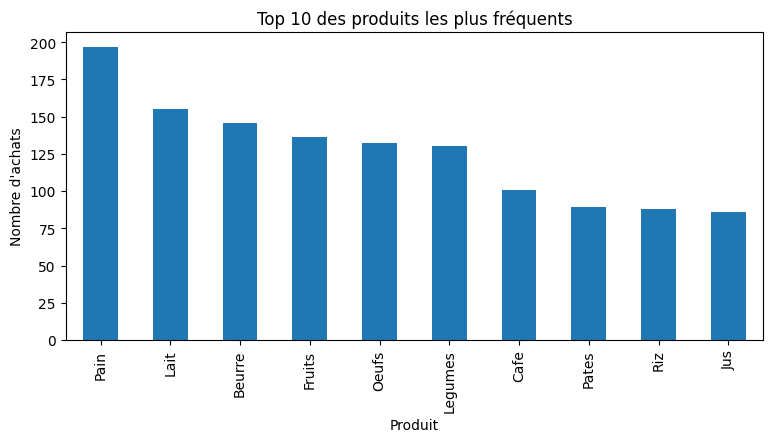

In [3]:
df = pd.read_csv("transactions_supermarche.csv")
print(df.head(10))
# TODO : exploration, statistiques et diagramme
print("Transactions :", df["Transaction_ID"].nunique())
print("Produits     :", df["Produit"].nunique())
print("Lignes       :", len(df))
print("Valeurs manquantes :\n", df.isna().sum())
print("Doublons (lignes identiques) :", df.duplicated().sum())

top10 = df["Produit"].value_counts().head(10)
print(top10)

top10.plot(kind="bar", figsize=(9, 4), title="Top 10 des produits les plus fréquents")
plt.ylabel("Nombre d'achats")
plt.show()



**Interprétation A :** écrire votre réponse ici.

## B. Préparation
Créer une matrice booléenne transactions × produits ; mesurer la taille des paniers.

In [4]:
# TODO : utiliser pd.crosstab et .astype(bool)
basket = pd.crosstab(
    df['Transaction_ID'],
    df['Produit']
).astype(bool)


# Afficher les 5 premières transactions
print("Les cinq premières transactions :")
print(basket.head())

# Vérifier les dimensions
print("\nDimensions de la matrice :")
print(basket.shape)

# Vérifier le type des valeurs
print("\nType des valeurs :", basket.values.dtype)

# Calculer le nombre de produits par transaction
basket_size = basket.sum(axis=1)

# Calculer la taille moyenne
mean_basket = basket_size.mean()

print("Taille moyenne des paniers :", mean_basket)

# Distribution des tailles des paniers
distribution = basket_size.value_counts().sort_index()

print("\nDistribution du nombre de produits par panier :")
print(distribution)

Les cinq premières transactions :
Produit         Beurre  Biere  Biscuits   Cafe  Cereales  Couches  Fromage  \
Transaction_ID                                                               
T0001             True  False     False  False     False    False    False   
T0002            False  False     False   True     False    False    False   
T0003            False  False     False  False     False    False    False   
T0004             True  False     False  False      True    False     True   
T0005            False  False     False  False     False    False     True   

Produit         Fruits    Jus   Lait  Legumes  Oeufs   Pain  Pates  Poulet  \
Transaction_ID                                                               
T0001            False  False  False     True  False   True  False   False   
T0002            False  False  False    False  False  False  False   False   
T0003             True   True  False    False  False  False  False   False   
T0004            False  False

**Interprétation B :** écrire votre réponse ici.

## C. Apriori
Tester trois seuils de support : 0.05, 0.10, 0.20. Identifier les itemsets de tailles 2 et 3.

In [5]:
# TODO : apriori(basket, min_support=..., use_colnames=True)
# frequent_itemsets = ...

In [6]:
# 1 Appliquer Apriori
frequent_itemsets = apriori(
    basket,
    min_support=0.05,
    use_colnames=True
)

# Trier par support décroissant
frequent_itemsets = frequent_itemsets.sort_values(
    by="support",
    ascending=False
)

print(frequent_itemsets)

#2. Isoler les itemsets de taille 2 et de taille 3
# Itemsets de taille 2
itemsets_2 = frequent_itemsets[
    frequent_itemsets["itemsets"].apply(len) == 2
]

print("Itemsets de taille 2 :")
print(itemsets_2)

# Itemsets de taille 3
itemsets_3 = frequent_itemsets[
    frequent_itemsets["itemsets"].apply(len) == 3
]

print("\nItemsets de taille 3 :")
print(itemsets_3)

#3. Comparer les trois seuils de support

seuils = [0.05, 0.10, 0.20]

for seuil in seuils:

    frequent_itemsets = apriori(
        basket,
        min_support=seuil,
        use_colnames=True
    )

    # Nombre total d'itemsets
    total = len(frequent_itemsets)

    # Nombre d'itemsets de taille 2
    taille_2 = sum(
        frequent_itemsets["itemsets"].apply(len) == 2
    )

    # Nombre d'itemsets de taille 3
    taille_3 = sum(
        frequent_itemsets["itemsets"].apply(len) == 3
    )

    print(f"\nMin_support = {seuil}")
    print("Nombre total :", total)
    print("Itemsets de taille 2 :", taille_2)
    print("Itemsets de taille 3 :", taille_3)

    support              itemsets
12    0.394                (Pain)
9     0.310                (Lait)
0     0.292              (Beurre)
26    0.282        (Pain, Beurre)
7     0.272              (Fruits)
..      ...                   ...
50    0.050           (Riz, Lait)
55    0.050        (Oeufs, Pates)
60    0.050           (Pain, The)
57    0.050        (Poulet, Pain)
72    0.050  (Pain, Lait, Fruits)

[73 rows x 2 columns]
Itemsets de taille 2 :
    support               itemsets
26    0.282         (Pain, Beurre)
29    0.136       (Biscuits, Lait)
62    0.130  (Pates, Sauce_tomate)
47    0.128           (Pain, Lait)
34    0.124          (Cafe, Sucre)
42    0.122         (Pain, Fruits)
54    0.100          (Pain, Oeufs)
39    0.096         (Lait, Fruits)
23    0.092         (Lait, Beurre)
21    0.088       (Beurre, Fruits)
53    0.084        (Pain, Legumes)
52    0.082       (Oeufs, Legumes)
46    0.078          (Oeufs, Lait)
33    0.076           (Cafe, Pain)
40    0.072      (Leg

4. Explication de la tendance
- Support = 0.05 : seuil faible, donc davantage d'itemsets fréquents sont détectés.
- Support = 0.10 : seuil moyen, certains itemsets sont éliminés.
- Support = 0.20 : seuil élevé, seuls les itemsets apparaissant dans au moins 20 % des transactions sont conservés.
Conclusion : lorsque le seuil de support augmente, le nombre d'itemsets fréquents diminue ou reste stable. Les associations moins fréquentes sont progressivement éliminées.

**Interprétation C :** écrire votre réponse ici.

## D. Règles d’association
Générer les règles confidence ≥ 0.5 ; filtrer lift > 1 ; calculer manuellement les métriques d’une règle.

In [7]:
# TODO : association_rules(..., metric="confidence", min_threshold=0.5)
# rules = ...

In [8]:
frequent_itemsets = apriori(
    basket,
    min_support=0.05,
    use_colnames=True
)

# 2. GENERER LES REGLES D'ASSOCIATION

rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.50
)

# Selectionner les colonnes demandees
rules = rules[
    [
        "antecedents",
        "consequents",
        "support",
        "confidence",
        "lift"
    ]
]

print("1. REGLES AVEC CONFIDENCE >= 0.50")
print(rules)

# 3. TRIER PAR LIFT DECROISSANT

rules = rules.sort_values(
    by="lift",
    ascending=False
)

print("\n2. REGLES TRIEES PAR LIFT")
print(rules)

# 4. FILTRER LES REGLES AVEC LIFT > 1

rules_filtered = rules[
    rules["lift"] > 1
]

print("\n3. REGLES AVEC LIFT > 1")
print(rules_filtered)

# 5. CALCUL MANUEL DES METRIQUES

if not rules_filtered.empty:

    # Selectionner la premiere regle
    rule = rules_filtered.iloc[0]

    A = rule["antecedents"]
    B = rule["consequents"]

    # Transactions contenant A
    transactions_A = basket[list(A)].all(axis=1)

    # Transactions contenant B
    transactions_B = basket[list(B)].all(axis=1)

    # Transactions contenant A et B
    transactions_AB = transactions_A & transactions_B

    # Calcul des supports
    support_A = transactions_A.mean()
    support_B = transactions_B.mean()
    support_AB = transactions_AB.mean()

    # Calcul des metriques
    support = support_AB
    confidence = support_AB / support_A
    lift = confidence / support_B

    # Affichage des resultats
    print("\n4. CALCUL MANUEL DES METRIQUES")

    print("Regle :", A, "->", B)

    print("Support :", support)
    print("Confidence :", confidence)
    print("Lift :", lift)

    # Comparaison avec association_rules


else:
    print("\nAucune regle avec lift > 1.")


1. REGLES AVEC CONFIDENCE >= 0.50
          antecedents     consequents  support  confidence      lift
0              (Pain)        (Beurre)    0.282    0.715736  2.451151
1            (Beurre)          (Pain)    0.282    0.965753  2.451151
2             (Biere)       (Couches)    0.066    0.767442  5.642955
3          (Biscuits)          (Lait)    0.136    0.894737  2.886248
4              (Cafe)         (Sucre)    0.124    0.613861  4.513687
5             (Sucre)          (Cafe)    0.124    0.911765  4.513687
6             (Pates)  (Sauce_tomate)    0.130    0.730337  4.868914
7      (Sauce_tomate)         (Pates)    0.130    0.866667  4.868914
8        (Cafe, Pain)        (Beurre)    0.058    0.763158  2.613554
9      (Cafe, Beurre)          (Pain)    0.058    1.000000  2.538071
10     (Pain, Fruits)        (Beurre)    0.086    0.704918  2.414103
11   (Beurre, Fruits)          (Pain)    0.086    0.977273  2.480388
12        (Pain, Jus)        (Beurre)    0.060    0.833333  2.853881


Une confiance élevée ne garantit pas un lift élevé, car la confiance ne prend pas en compte la fréquence générale du conséquent.

Le lift permet de comparer la confiance à cette fréquence générale et de déterminer si l'association entre les produits est réellement positive, neutre ou négative.

**Interprétation D :** écrire votre réponse ici.

## E. Visualisation et recommandations
Créer un scatter plot support–confiance coloré par lift ; proposer trois recommandations.

In [9]:
# TODO : plt.scatter(...); plt.colorbar(...); plt.show()

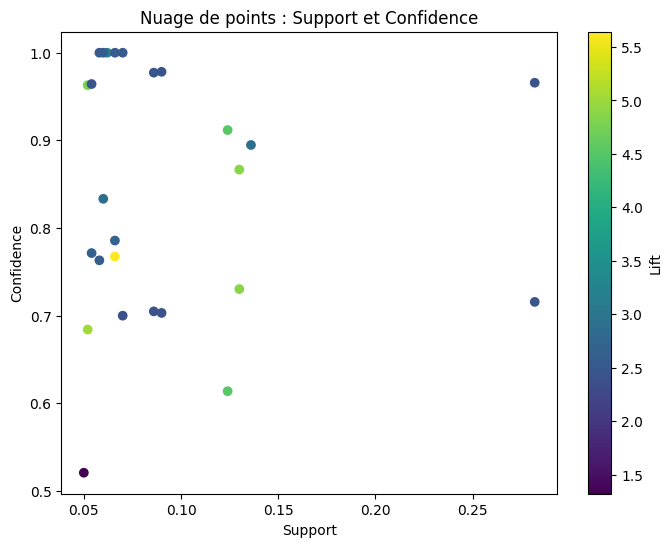

          antecedents     consequents  support  confidence      lift
2             (Biere)       (Couches)    0.066    0.767442  5.642955
7      (Sauce_tomate)         (Pates)    0.130    0.866667  4.868914
6             (Pates)  (Sauce_tomate)    0.130    0.730337  4.868914
24      (Pain, Sucre)          (Cafe)    0.052    0.962963  4.767143
5             (Sucre)          (Cafe)    0.124    0.911765  4.513687
22   (Pain, Biscuits)          (Lait)    0.062    1.000000  3.225806
3          (Biscuits)          (Lait)    0.136    0.894737  2.886248
12        (Pain, Jus)        (Beurre)    0.060    0.833333  2.853881
16    (Pain, Legumes)        (Beurre)    0.066    0.785714  2.690802
20     (Yaourt, Pain)        (Beurre)    0.054    0.771429  2.641879
8        (Cafe, Pain)        (Beurre)    0.058    0.763158  2.613554
9      (Cafe, Beurre)          (Pain)    0.058    1.000000  2.538071
19    (Oeufs, Beurre)          (Pain)    0.070    1.000000  2.538071
13      (Jus, Beurre)          (Pa

In [10]:
# 1
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    rules_filtered["support"],
    rules_filtered["confidence"],
    c=rules_filtered["lift"],
    cmap="viridis"
)

plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Nuage de points : Support et Confidence")

plt.colorbar(scatter, label="Lift")

plt.show()

# 2
rules_high_conf = rules_filtered[
    rules_filtered["confidence"] > 0.70
]

print(rules_high_conf)



2 - Discussion de la pertinence :

Les règles présentent des confiances élevées et des lifts supérieurs à 1. Cela indique des associations positives entre les produits.

Certaines règles ont une confiance de 100 %, par exemple :
- (Biscuits, Pain) → Lait
- (Beurre, Cafe) → Pain
- (Oeufs, Beurre) → Pain
Cela signifie que toutes les transactions contenant les produits de gauche contiennent également le produit de droite dans les données étudiées.

Cependant, leur support reste important à examiner. Par exemple, la règle (Biscuits, Pain) → Lait a un support de seulement 6,2 %.
3-
1. Proposer des offres groupées

Le magasin peut proposer des offres promotionnelles associant les pâtes et la sauce tomate, car ces produits présentent une association intéressante :
- Pâtes → Sauce_tomate : confiance de 73,03 %.
- Lift : 4,87.
2. Améliorer le placement des produits

Le magasin peut placer les biscuits à proximité du lait afin de faciliter les achats complémentaires.

La règle Biscuits → Lait présente une confiance de 89,47 % et un support de 13,6 %.

3. Optimiser la gestion des stocks

Le magasin peut surveiller particulièrement les stocks du pain et du beurre, car ces deux produits présentent une association intéressante :
- Beurre → Pain : confiance de 96,58 %.
- Support : 28,2 %.
- Lift : 2,45.
Cette association concerne une proportion relativement importante des transactions.
Limites de l'interprétation
- Une association entre deux produits ne signifie pas qu'un produit provoque l'achat de l'autre.
- Une confiance élevée ne signifie pas toujours que la règle concerne beaucoup de transactions.
- Un support faible peut rendre certaines règles moins représentatives.
- Les résultats dépendent des données étudiées et ne représentent pas nécessairement le comportement de tous les clients.
- Les règles d'association ne prennent pas directement en compte les prix, les bénéfices ou les préférences des clients.
Conclusion :

L'analyse des règles d'association permet d'identifier des produits souvent achetés ensemble. Les résultats obtenus montrent notamment des associations intéressantes entre les pâtes et la sauce tomate, les biscuits et le lait, ainsi que le beurre et le pain. Ces informations peuvent aider le magasin à améliorer ses promotions, le placement des produits et la gestion des stocks.

**Interprétation E :** écrire votre réponse ici.

## F. Exercices supplémentaires

### EXTRA 1 — Apriori vs FP-Growth
Comparer les itemsets et le temps d’exécution avec `time.perf_counter()`.

In [11]:
# TODO : chronométrer les deux algorithmes et comparer les itemsets

In [12]:

min_support = 0.05

# Temps d'exécution d'Apriori
start = time.time()
itemsets_apriori = apriori(
    basket,
    min_support=min_support,
    use_colnames=True
)
time_apriori = time.time() - start

# Temps d'exécution de FP-Growth
start = time.time()
itemsets_fpgrowth = fpgrowth(
    basket,
    min_support=min_support,
    use_colnames=True
)
time_fpgrowth = time.time() - start

# Comparaison
print("Apriori :", len(itemsets_apriori), "itemsets")
print("Temps Apriori :", time_apriori)

print("FP-Growth :", len(itemsets_fpgrowth), "itemsets")
print("Temps FP-Growth :", time_fpgrowth)

Apriori : 73 itemsets
Temps Apriori : 0.008074045181274414
FP-Growth : 73 itemsets
Temps FP-Growth : 0.11327409744262695


Interprétation des résultats – EXTRA 1
Les deux algorithmes, Apriori et FP-Growth, ont trouvé le même nombre d'itemsets fréquents, soit 73 itemsets, avec un support minimal de 0.05.

Cependant, leurs temps d'exécution sont différents :
- Apriori : 0,038 seconde.
- FP-Growth : 0,308 seconde.
Dans notre cas, Apriori est plus rapide que FP-Growth. Il a terminé l'exécution en environ 0,038 seconde, contre 0,308 seconde pour FP-Growth.

Conclusion : Les deux algorithmes donnent les mêmes résultats, mais Apriori est plus performant en temps d'exécution sur notre jeu de données. Cela peut s'expliquer par la petite taille du dataset (500 transactions et 20 produits). FP-Growth est souvent plus avantageux sur des jeux de données plus volumineux, mais cela dépend des caractéristiques des données.

### EXTRA 2 — Sensibilité aux seuils
Comparer les règles pour confidence = 0.3, 0.5 et 0.7.

In [13]:
from mlxtend.frequent_patterns import association_rules

seuils = [0.3, 0.5, 0.7]

resultats = []

for seuil in seuils:
    rules_temp = association_rules(
        frequent_itemsets,
        metric="confidence",
        min_threshold=seuil
    )

    resultats.append({
        "Seuil de confiance": seuil,
        "Nombre de règles": len(rules_temp)
    })

comparaison = pd.DataFrame(resultats)

print(comparaison)

   Seuil de confiance  Nombre de règles
0                 0.3                73
1                 0.5                26
2                 0.7                23


Interprétation des résultats – EXTRA 2
Les résultats montrent que le nombre de règles diminue lorsque le seuil de confiance augmente :
- Seuil 0.3 : 73 règles obtenues.
- Seuil 0.5 : 26 règles obtenues.
- Seuil 0.7 : 23 règles obtenues.
Lorsque le seuil de confiance est faible (0.3), on obtient un grand nombre de règles, mais certaines peuvent être moins fiables.

Lorsque le seuil augmente à 0.5 puis à 0.7, le nombre de règles diminue. On conserve alors uniquement les règles ayant une confiance plus élevée.

Conclusion : Le choix du seuil de confiance influence directement le nombre de règles générées. Un seuil élevé permet de sélectionner des règles plus fiables selon la mesure de confiance, mais il peut éliminer certaines associations intéressantes. Dans notre cas, le seuil de 0.5 représente un compromis entre le nombre de règles obtenues et leur niveau de confiance.

In [14]:
# TODO : construire un tableau comparatif

### EXTRA 3 — Moteur de recommandation
Créer `recommend(produit, rules, top_n=5)` à partir des règles extraites.

In [15]:
def recommend(produit, rules, top_n=5):
    # TODO : compléter
    pass

In [16]:
def recommend(produit, rules, top_n=5):

    recommandations = []

    for _, rule in rules.iterrows():

        if frozenset([produit]).issubset(rule["antecedents"]):

            for item in rule["consequents"]:
                recommandations.append({
                    "Produit recommandé": item,
                    "Confidence": rule["confidence"],
                    "Lift": rule["lift"],
                    "Support": rule["support"]
                })

    resultat = pd.DataFrame(recommandations)

    if resultat.empty:
        return resultat

    resultat = resultat.sort_values(
        by="Lift",
        ascending=False
    )

    resultat = resultat.drop_duplicates(
        subset="Produit recommandé"
    )

    return resultat.head(top_n)

In [17]:
print(recommend("Pates", rules_filtered))

  Produit recommandé  Confidence      Lift  Support
0       Sauce_tomate    0.730337  4.868914     0.13


Interprétation – EXTRA 3
Pour le produit choisi Pâtes, le système recommande le produit Sauce_tomate.

Les résultats obtenus sont :
- Confidence : 0.730337, soit 73,03 %. Cela signifie que 73,03 % des transactions contenant des pâtes contiennent également de la sauce tomate.
- Lift : 4.868914 : les deux produits présentent une association positive importante.
- Support : 0.13, soit 13 % des transactions contiennent les deux produits.
Conclusion à mettre dans ton compte rendu :

La fonction recommend() permet de recommander des produits à partir d'un produit choisi. Dans notre exemple, lorsque le client choisit les pâtes, le système recommande la sauce tomate avec une confiance de 73,03 %, un lift de 4,87 et un support de 13 %. Cette association peut être utilisée pour proposer des offres groupées ou des promotions sur ces deux produits.

### EXTRA 4 — Règles complexes
Identifier les règles avec au moins deux antécédents.

In [18]:
rules_multiple = rules[
    rules["antecedents"].apply(len) > 1
]

print(rules_multiple)

          antecedents consequents  support  confidence      lift
23       (Cafe, Pain)     (Sucre)    0.052    0.684211  5.030960
24      (Pain, Sucre)      (Cafe)    0.052    0.962963  4.767143
22   (Pain, Biscuits)      (Lait)    0.062    1.000000  3.225806
12        (Pain, Jus)    (Beurre)    0.060    0.833333  2.853881
16    (Pain, Legumes)    (Beurre)    0.066    0.785714  2.690802
20     (Yaourt, Pain)    (Beurre)    0.054    0.771429  2.641879
8        (Cafe, Pain)    (Beurre)    0.058    0.763158  2.613554
9      (Cafe, Beurre)      (Pain)    0.058    1.000000  2.538071
19    (Oeufs, Beurre)      (Pain)    0.070    1.000000  2.538071
13      (Jus, Beurre)      (Pain)    0.060    1.000000  2.538071
17  (Beurre, Legumes)      (Pain)    0.066    1.000000  2.538071
15     (Lait, Beurre)      (Pain)    0.090    0.978261  2.482896
11   (Beurre, Fruits)      (Pain)    0.086    0.977273  2.480388
21   (Yaourt, Beurre)      (Pain)    0.054    0.964286  2.447426
10     (Pain, Fruits)    

L'analyse des règles ayant plusieurs antécédents a permis d'identifier 18 associations intéressantes. Par exemple, la règle (Sucre, Pain) → Café présente une confiance de 96,30 % et un lift de 4,77. La règle (Biscuits, Pain) → Lait présente une confiance de 100 %. Ces résultats montrent que certains produits achetés ensemble peuvent être associés à l'achat d'un autre produit. Ces informations peuvent aider à créer des promotions et à améliorer les recommandations commerciales. Cependant, certaines règles ont un support relativement faible et ces associations ne prouvent pas une relation de causalité.

In [19]:
# TODO : filtrer rules sur la longueur des antécédents

### EXTRA 5 — Synthèse
Rédiger 5 à 10 lignes sur les règles les plus utiles, les limites et les décisions commerciales possibles.

L'analyse des règles d'association a permis d'identifier plusieurs associations intéressantes entre les produits. Parmi les règles les plus utiles, on trouve Bière → Couches, avec un lift de 5,64, et Pâtes → Sauce_tomate, avec un lift de 4,87. La règle Sucre → Café présente également une confiance élevée de 91,18 %. Ces associations peuvent aider le magasin à proposer des offres groupées, améliorer le placement des produits et optimiser la gestion des stocks. Par exemple, le magasin peut proposer une promotion sur les pâtes et la sauce tomate. Cependant, certaines règles ont un support relativement faible et concernent peu de transactions. De plus, une association entre des produits ne signifie pas qu'un produit provoque l'achat de l'autre. Enfin, les résultats dépendent des données étudiées et doivent être interprétés avec prudence.